# Rotrends w/w on Monday 12 Oct 2026: the +4.7% platform and -15% Steal An Egg

**Question:** the Platform CCU dashboard (Tableau, *RBLX Engagement > Platform CCU Dashboard*) showed Rotrends **+4.7% w/w** for Mon 12 Oct and Steal An Egg about **-15%**. Is that a data artefact or a real trend?

### Takeaways (data to 12 Oct 11:50 UTC; re-running pulls the latest)
- **The dashboard's two numbers are for 12 Oct so far, not a full day.** They compare the first 60 ten-minute snapshots (00:00-09:50 UTC) with the same snapshots on 5 Oct, and that reproduces them exactly: **+4.71%** and **-15.21%**. By 11:50 UTC they were +4.4% and -14.8%.
- **12 Oct is Columbus Day (US) and Thanksgiving (Canada), and that Monday is up 11-16% w/w every year** (2023 +15.8%, 2024 +11.0%, 2025 +11.6%). The Fri-Sun around it ranged from -5% to +6%, so the holiday adds about 10-13pp.
- **Today's platform +4.7% is the start of the holiday effect, and the biggest part is still to come.**
  - **Overnight lift:** **01:00-05:00 UTC (9pm-1am ET, Sunday night in the US)** is up 5-9%, the same lift as in past years.
  - **Daytime lift:** in past years most of the gain came in the **US daytime (14:00-20:00 UTC)**, at +14% to +32% w/w. Those are also the busiest hours, and they haven't happened yet.
  - **Projection:** applying each past year's hourly holiday pattern to the remaining hours gives a full day of **+9.6% to +13.9%**. A flat afternoon would give +1.9%.
  - **But 2026 is running weaker so far:** +4.4% against +6.6% to +9.9% for the same hours in past years. A day that stays proportionally weaker would end below the past-year range.
- **Steal An Egg's -15% is a real decline, not an artefact,** and it comes on a day when the platform is getting a holiday lift.
  - Every hour so far is down 11-19%, and the full weekend days were already down (Sat -5.7%, Sun -7.9%).
  - Rotrends, the SRS scan and Rolimons agree on its level every day since 20 Sep.
  - The game fell 18% in the week to 4 Oct, held flat the next week, and has weakened again since Saturday.
  - Copies of the game more than doubled w/w combined (76k to 165k CCU), led by Break and Steal an Egg (23k to 72k). That is small against the main game's 1.5M.
- **The per-game Rotrends total was +1.0% over the latest full week.**
  - **Gains, confirmed by SRS and Rolimons:** Huss Valley, Halloween updates (Dandy's World, Adopt Me, 99 Nights) and new games.
  - **Declines, also confirmed:** Project Slayers 2, Ride A Pet, Blox Fruits.
  - **Rotrends understates several established games:** it shows Brookhaven, Murder Mystery 2, RIVALS, Jujutsu Shenanigans and Steal a Brainrot down 8-16%, where SRS and Rolimons are flat (-4% to +2%).

In [1]:
import os
import warnings
from decimal import Decimal

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd
import snowflake.connector

warnings.filterwarnings("ignore", category=DeprecationWarning)

DAY = pd.Timestamp("2026-10-12")  # the dashboard day in question (UTC)
BASE = DAY - pd.Timedelta(days=7)  # same weekday a week earlier
WEEK_END = DAY - pd.Timedelta(days=DAY.weekday() + 1)  # latest complete Monday-to-Sunday week
WEEK_START = WEEK_END - pd.Timedelta(days=6)
STEAL_AN_EGG = 10563114921
SNAPSHOTS_PER_DAY = 144  # rotrends publishes a point every 10 minutes
DASHBOARD_SNAPSHOTS = 60  # what the dashboard had for 12 Oct when it showed +4.7% (00:00-09:50 UTC)
ET_OFFSET = -4  # US Eastern (EDT) hours from UTC in October

# Validated reference palette (dataviz skill): categorical slots 1-3, muted ink for context.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, MUTED, GRID, SHADE = "#0b0b0b", "#52514e", "#898781", "#e6e5e1", "#f0efec"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": MUTED, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.titlecolor": INK, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.axisbelow": True, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": GRID, "grid.linewidth": 0.8, "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
})
SERIES_COLOR = {"Platform": BLUE, "Steal An Egg": ORANGE}

conn = snowflake.connector.connect(
    connection_name=os.getenv("SNOWFLAKE_CONNECTION", "default"),
)


def q(sql: str) -> pd.DataFrame:
    df = conn.cursor().execute(sql).fetch_pandas_all()
    df.columns = [c.lower() for c in df.columns]
    for c in df:
        if c in ("date", "ts"):
            df[c] = pd.to_datetime(df[c])
        elif df[c].dtype == object and isinstance(df[c].dropna().iloc[0] if df[c].notna().any() else None, Decimal):
            df[c] = df[c].astype(float)  # Snowflake NUMBER arrives as Decimal
    return df


def pct_axis(ax, decimals=0):
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(1, decimals=decimals))


def source_note(fig, text):
    fig.text(0.01, 0.005, text, fontsize=8, color=MUTED, ha="left", va="bottom")

Initiating login request with your identity provider. A browser window should have opened for you to complete the login. If you can't see it, check existing browser windows, or your OS settings. Press CTRL+C to abort and try again...


## 1. Where the numbers come from

Rotrends reaches us through three feeds, which is why the platform total has intraday readings while most games have one a day:

| Feed | Table | Grain |
|---|---|---|
| Platform total (rotrends.com "Players Right Now") | `rotrends_platform_ccu` | every 10 min, loaded hourly. `player_trend` datasource `Rotrends Platform` (its `hour_et` column is the UTC hour) |
| Every listed game | `rotrend_list` -> `rotrend_games_adj` | one snapshot per game per day at 00:00 UTC, scaled to a daily average by a day-of-week ratio |
| Core games | `rotrends_core_games` | every 10 min per game. Currently only **Steal An Egg** |

The dashboard's line is the 10-minute platform series, and its Steal An Egg view is the core-game series. Both are drawn per **UTC day**.

**How the dashboard's w/w works:** the day's snapshots so far against the **same snapshots a week earlier**. On 12 Oct's first 60 snapshots this reproduces the dashboard exactly. Comparing the ratio of sums with the mean of each snapshot's growth gives almost the same answer, because CCU varies little across these hours.

In [2]:
platform = q(f'''
    SELECT process_timestamp AS ts, playing
    FROM bots.rblx.rotrends_platform_ccu
    WHERE process_timestamp >= DATEADD(day, -28, '{DAY:%Y-%m-%d}')
    QUALIFY ROW_NUMBER() OVER (PARTITION BY process_timestamp ORDER BY file_name DESC) = 1
''')
egg = q(f'''
    SELECT process_timestamp AS ts, playing
    FROM bots.rblx.rotrends_core_games
    WHERE universe_id = {STEAL_AN_EGG}
        AND process_timestamp >= DATEADD(day, -28, '{DAY:%Y-%m-%d}')
    QUALIFY ROW_NUMBER() OVER (PARTITION BY universe_id, process_timestamp ORDER BY file_name DESC) = 1
''')
series = {
    name: df.set_index("ts")["playing"].astype(float).sort_index()
    for name, df in [("Platform", platform), ("Steal An Egg", egg)]
}


def day_points(s: pd.Series, day: pd.Timestamp) -> pd.Series:
    """The day's 10-minute points, indexed by slot 0-143 from 00:00 UTC."""
    x = s[s.index.normalize() == day]
    return pd.Series(x.values, index=((x.index - day).total_seconds() // 600).astype(int))


def matched_ww(s: pd.Series, day: pd.Timestamp, n: int | None = None) -> tuple[float, float, int]:
    """Dashboard-style w/w: the day's first n snapshots against the same snapshots a week earlier.
    Returns (ratio of sums, mean of per-snapshot growth, snapshots used)."""
    cur, base = day_points(s, day), day_points(s, day - pd.Timedelta(days=7))
    if n:
        cur = cur.iloc[:n]
    common = cur.index.intersection(base.index)
    return cur[common].sum() / base[common].sum() - 1, (cur[common] / base[common] - 1).mean(), len(common)


rows = []
for name, s in series.items():
    today = day_points(s, DAY)
    dash_sum, dash_mean, _ = matched_ww(s, DAY, DASHBOARD_SNAPSHOTS)
    now_sum, now_mean, n_now = matched_ww(s, DAY)
    prev_sum, _, _ = matched_ww(s, DAY - pd.Timedelta(days=1))
    rows.append({
        "series": name,
        "snapshots so far": len(today),
        f"w/w, first {DASHBOARD_SNAPSHOTS} (dashboard)": dash_sum,
        f"same, mean of snapshot growth": dash_mean,
        "w/w, all snapshots so far": now_sum,
        "naive: partial day avg vs full day a week ago": today.mean() / day_points(s, BASE).mean() - 1,
        f"{DAY - pd.Timedelta(days=1):%a %d %b} (full day)": prev_sum,
    })
ww_table = pd.DataFrame(rows).set_index("series")
print(f"{DAY:%a %d %b} vs {BASE:%a %d %b}; latest platform point {series['Platform'].index.max():%d %b %H:%M} UTC")
ww_table.style.format({c: "{:+.2%}" for c in ww_table.columns if c != "snapshots so far"})

Mon 12 Oct vs Mon 05 Oct; latest platform point 12 Oct 17:50 UTC


,snapshots so far,"w/w, first 60 (dashboard)","same, mean of snapshot growth","w/w, all snapshots so far",naive: partial day avg vs full day a week ago,Sun 11 Oct (full day)
series,,,,,,
Platform,108,+4.71%,+4.68%,+7.40%,+6.69%,+0.63%
Steal An Egg,108,-15.21%,-15.12%,-10.01%,-2.62%,-7.88%


## 2. Which hours drive it

Hourly averages of the 10-minute points for the day against the same hours a week earlier. Hour labels are UTC with US Eastern underneath.
- **Platform:** the gain is concentrated in **01:00-05:00 UTC (9pm-1am ET, Sunday night in the US)**. From about 07:00 UTC it is roughly zero.
  - 12 Oct is Columbus Day in the US and Thanksgiving in Canada. Section 3 shows the same Sunday-night bump on the holiday in each of the last three years.
- **Steal An Egg:** down in **every** hour, so this is not one odd reading or a low-count effect.

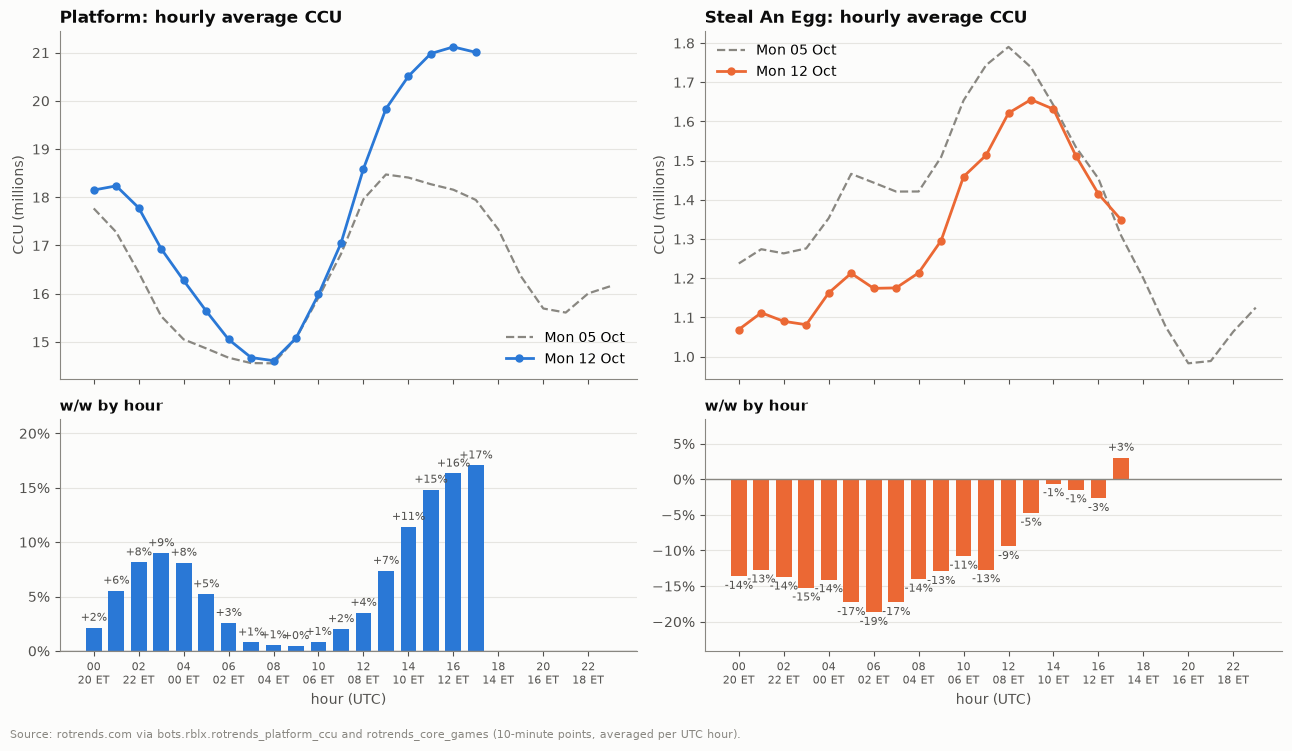

In [3]:
def hourly(s: pd.Series, day: pd.Timestamp) -> pd.Series:
    x = day_points(s, day)
    return x.groupby(x.index // 6).mean()


def matched_hourly(s: pd.Series, day: pd.Timestamp) -> pd.DataFrame:
    """Per UTC hour, the summed CCU of the day's snapshots and of the same snapshots a week earlier.
    Only snapshots present on both days count (12 of 05 Oct's snapshots are missing), as on the dashboard."""
    cur, base = day_points(s, day), day_points(s, day - pd.Timedelta(days=7))
    common = cur.index.intersection(base.index)
    return pd.DataFrame({"cur": cur[common], "base": base[common]}).groupby(common // 6).sum()


fig, axes = plt.subplots(2, 2, figsize=(13, 7.5), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
for col, (name, s) in enumerate(series.items()):
    color = SERIES_COLOR[name]
    cur, base = hourly(s, DAY), hourly(s, BASE)
    ax = axes[0, col]
    ax.plot(base.index, base / 1e6, color=MUTED, ls="--", lw=1.6, label=f"{BASE:%a %d %b}")
    ax.plot(cur.index, cur / 1e6, color=color, marker="o", markersize=5, label=f"{DAY:%a %d %b}")
    ax.set_title(f"{name}: hourly average CCU")
    ax.set_ylabel("CCU (millions)")
    ax.legend(loc="lower right" if name == "Platform" else "upper left")
    m = matched_hourly(s, DAY)
    ww = m["cur"] / m["base"] - 1
    ax = axes[1, col]
    ax.bar(ww.index, ww, width=0.7, color=color)
    ax.axhline(0, color=MUTED, lw=1)
    for h, v in ww.items():
        ax.annotate(f"{v:+.0%}", (h, v), xytext=(0, 3 if v >= 0 else -3), textcoords="offset points",
                    ha="center", va="bottom" if v >= 0 else "top", fontsize=8, color=INK2)
    ax.set_title("w/w by hour", fontsize=11)
    pct_axis(ax)
    ax.margins(y=0.25)
    ax.set_xticks(range(0, 24, 2))
    ax.set_xticklabels([f"{h:02d}\n{(h + ET_OFFSET) % 24:02d} ET" for h in range(0, 24, 2)], fontsize=8)
    ax.set_xlabel("hour (UTC)")
source_note(fig, "Source: rotrends.com via bots.rblx.rotrends_platform_ccu and rotrends_core_games (10-minute points, averaged per UTC hour).")
fig.tight_layout(rect=(0, 0.03, 1, 1))

## 3. Columbus Day in past years

Columbus Day (US) and Thanksgiving (Canada) fall on the second Monday of October: 9 Oct 2023, 14 Oct 2024, 13 Oct 2025 and 12 Oct 2026.
- **2023-2025:** the SRS scan (`player_trend` datasource `SRS`, 2-hourly snapshots). It covers all three years, while the Rotrends platform series starts on 11 Oct 2024, too late for that year's week-earlier comparison. For 2025, Rotrends gives +10.9% for the Monday against the scan's +11.6%.
- **2026:** the scan for Fri-Sun. Monday is not scanned yet, so it uses the Rotrends platform series on matched snapshots, as the dashboard does, and is partial.

Each day is compared with the same weekday a week earlier.

In [4]:
COLUMBUS_DAYS = {2023: pd.Timestamp("2023-10-09"), 2024: pd.Timestamp("2024-10-14"),
                 2025: pd.Timestamp("2025-10-13"), 2026: DAY}
YEAR_STYLE = {2023: (BLUE, "o"), 2024: (ORANGE, "s"), 2025: (AQUA, "^"), 2026: (INK, "D")}
REL_DAYS = {-3: "Fri", -2: "Sat", -1: "Sun", 0: "Mon (holiday)", 1: "Tue"}
windows = " OR ".join(f"date BETWEEN '{d - pd.Timedelta(days=11):%Y-%m-%d}' AND '{d + pd.Timedelta(days=1):%Y-%m-%d}'"
                      for d in COLUMBUS_DAYS.values())
scan = q(f'''
    SELECT date, hour_et AS hour_utc, players
    FROM bots.rblx.player_trend
    WHERE datasource = 'SRS' AND ({windows})
''')
scan_hourly = scan.pivot_table(index="date", columns="hour_utc", values="players")
scan_complete = scan_hourly.notna().sum(axis=1) == 12  # 2-hourly scan: 12 snapshots a day

rows, partial = {}, {}
for year, hol in COLUMBUS_DAYS.items():
    r = {}
    for off, label in REL_DAYS.items():
        d, b = hol + pd.Timedelta(days=off), hol + pd.Timedelta(days=off - 7)
        if scan_complete.get(d, False) and scan_complete.get(b, False):
            r[label] = scan_hourly.loc[d].mean() / scan_hourly.loc[b].mean() - 1
        elif d == DAY:
            r[label] = matched_ww(series["Platform"], DAY)[0]
            partial[year] = label
    rows[year] = r
holiday_ww = pd.DataFrame(rows).T.reindex(columns=list(REL_DAYS.values()))
holiday_ww.index.name = "year"
print(f"2026 Monday: Rotrends platform, {len(day_points(series['Platform'], DAY))} of {SNAPSHOTS_PER_DAY} snapshots so far, "
      f"{matched_ww(series['Platform'], DAY)[2]} of them matched a week earlier")
holiday_ww.style.format("{:+.1%}", na_rep="")

2026 Monday: Rotrends platform, 108 of 144 snapshots so far, 96 of them matched a week earlier


,Fri,Sat,Sun,Mon (holiday),Tue
year,,,,,
2023,+5.6%,+3.0%,+2.9%,+15.8%,
2024,-3.1%,-4.6%,-2.3%,+11.0%,+3.1%
2025,+0.4%,-1.1%,+0.9%,+11.6%,+10.6%
2026,+6.1%,+0.5%,+0.2%,+7.4%,


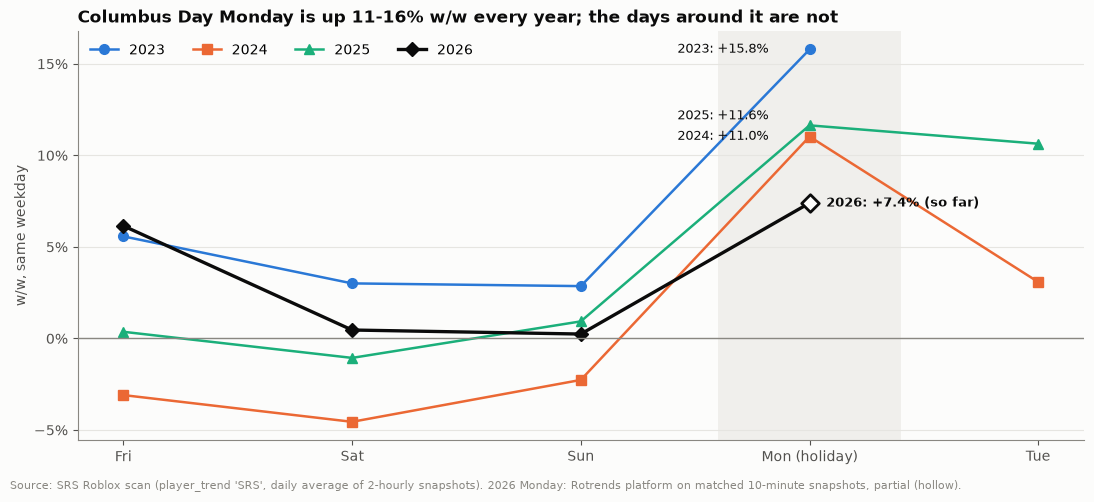

In [5]:
fig, ax = plt.subplots(figsize=(11, 5))
x = range(len(REL_DAYS))
ax.axvspan(2.6, 3.4, color=SHADE, lw=0, zorder=0)
for year, (color, marker) in YEAR_STYLE.items():
    vals = holiday_ww.loc[year]
    is_now = year == max(COLUMBUS_DAYS)
    ax.plot(x, vals.values, color=color, marker=marker, markersize=7, lw=2.4 if is_now else 1.8, label=str(year))
    if year in partial:
        i = list(REL_DAYS.values()).index(partial[year])
        ax.scatter([i], [vals.iloc[i]], s=80, facecolor="#fcfcfb", edgecolor=color, linewidth=2, zorder=4, marker=marker)
mon = holiday_ww["Mon (holiday)"].dropna().sort_values()
lo, hi = ax.get_ylim()
label_y = []
for year, v in mon.items():
    if year in partial:  # right of its point, clear of the other years' lines
        ax.annotate(f"{year}: {v:+.1%} (so far)", (3, v), xytext=(12, 0), textcoords="offset points", ha="left",
                    va="center", fontsize=9, color=INK, fontweight="bold")
        continue
    y = v if not label_y else max(v, label_y[-1] + 0.05 * (hi - lo))
    label_y.append(y)
    ax.annotate(f"{year}: {v:+.1%}", (3, v), xytext=(2.82, y), textcoords="data", ha="right", va="center",
                fontsize=9, color=INK)
ax.axhline(0, color=MUTED, lw=1)
ax.set_xticks(list(x))
ax.set_xticklabels(list(REL_DAYS.values()))
ax.yaxis.set_major_locator(mticker.MultipleLocator(0.05))
pct_axis(ax)
ax.set_ylabel("w/w, same weekday")
ax.set_title("Columbus Day Monday is up 11-16% w/w every year; the days around it are not")
ax.legend(loc="upper left", ncols=4)
source_note(fig, "Source: SRS Roblox scan (player_trend 'SRS', daily average of 2-hourly snapshots). "
                 "2026 Monday: Rotrends platform on matched 10-minute snapshots, partial (hollow).")
fig.tight_layout(rect=(0, 0.03, 1, 1))

**By hour.** The holiday Monday's w/w at each UTC hour. 2023-2025 come from the 2-hourly scan; 2026 so far comes from Rotrends' hourly averages on matched snapshots.
- **02:00-05:00 UTC (10pm-1am ET, Sunday night):** a first lift, as US players stay up before the day off.
- **06:00-12:00 UTC (US overnight):** a dip.
- **14:00-20:00 UTC (10am-4pm ET):** the largest lift, with US children home during the day. This is most of the day's gain, and the busiest hours of the day.

2023: same hours as 2026 so far,2024: same hours as 2026 so far,2025: same hours as 2026 so far,2026 so far
+14.5%,+10.3%,+9.5%,+7.4%


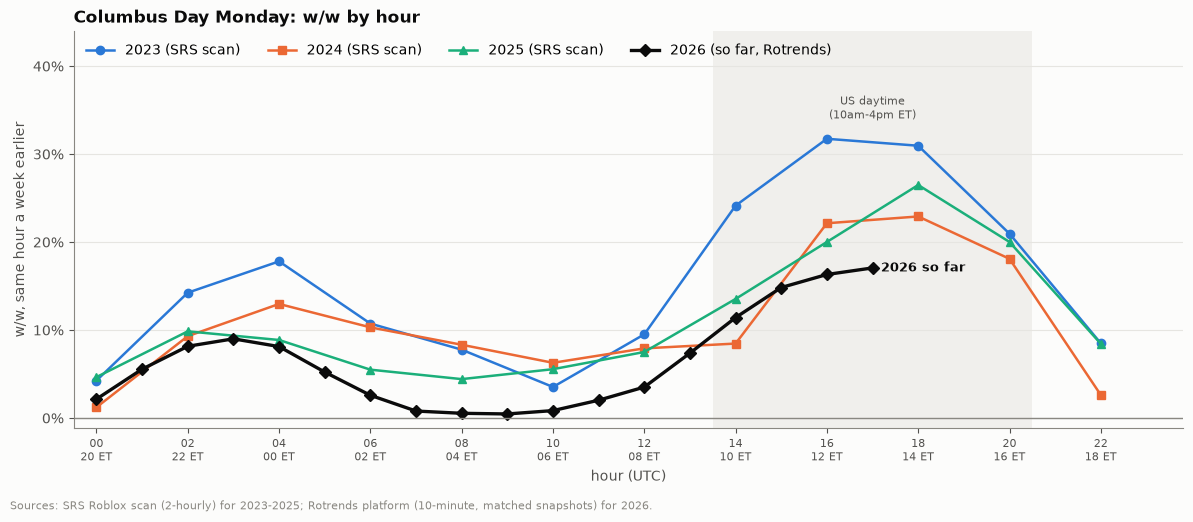

In [6]:
hol_pattern = {}  # holiday-Monday w/w by UTC hour, gaps between 2-hourly snapshots interpolated
fig, ax = plt.subplots(figsize=(12, 5.2))
for year, hol in COLUMBUS_DAYS.items():
    color, marker = YEAR_STYLE[year]
    if year == max(COLUMBUS_DAYS):
        m = matched_hourly(series["Platform"], DAY)
        g = m["cur"] / m["base"] - 1
        ax.plot(g.index, g, color=color, marker=marker, markersize=6, lw=2.4, label=f"{year} (so far, Rotrends)")
        ax.annotate(f"{year} so far", (g.index[-1], g.iloc[-1]), xytext=(6, 0), textcoords="offset points",
                    va="center", fontsize=9, color=INK, fontweight="bold")
    else:
        g = (scan_hourly.loc[hol] / scan_hourly.loc[hol - pd.Timedelta(days=7)] - 1).dropna()
        hol_pattern[year] = g.reindex(range(24)).interpolate(limit_direction="both")
        ax.plot(g.index, g, color=color, marker=marker, markersize=6, lw=1.8, label=f"{year} (SRS scan)")
ax.axvspan(13.5, 20.5, color=SHADE, lw=0, zorder=0)
ax.set_ylim(top=0.44)
ax.text(17, 0.84, "US daytime\n(10am-4pm ET)", transform=ax.get_xaxis_transform(), ha="center", va="top",
        fontsize=8, color=INK2)
ax.axhline(0, color=MUTED, lw=1)
pct_axis(ax)
ax.set_xticks(range(0, 24, 2))
ax.set_xticklabels([f"{h:02d}\n{(h + ET_OFFSET) % 24:02d} ET" for h in range(0, 24, 2)], fontsize=8)
ax.set_xlim(-0.5, 23.8)
ax.set_xlabel("hour (UTC)")
ax.set_ylabel("w/w, same hour a week earlier")
ax.set_title("Columbus Day Monday: w/w by hour")
ax.legend(loc="upper left", ncols=4)
source_note(fig, "Sources: SRS Roblox scan (2-hourly) for 2023-2025; Rotrends platform (10-minute, matched snapshots) for 2026.")
fig.tight_layout(rect=(0, 0.03, 1, 1))

so_far = matched_hourly(series["Platform"], DAY).index
pd.DataFrame({f"{y}: same hours as 2026 so far": [p.loc[so_far].mean()] for y, p in hol_pattern.items()}
             | {"2026 so far": [matched_ww(series["Platform"], DAY)[0]]}).style.format("{:+.1%}").hide(axis="index")

## 4. How the day's w/w will move as the remaining hours arrive

The solid line is the dashboard's day-to-date w/w after each hour, using the ratio of sums. The dashed lines continue it to midnight UTC under different assumptions for the hours still to come.
- **Platform:** the remaining hours follow each past year's holiday pattern by hour (section 3). A flat 0% line is shown for reference.
  - 2026 is running below every past year in the hours so far. A day that stays proportionally weaker would land below the past-year lines.
- **Steal An Egg:** flat, half its current decline, or its current decline.
- The figure dilutes steadily as hours are added. Weighting makes almost no difference: the ratio of sums and the mean of hourly growth end within about 0.1pp of each other.

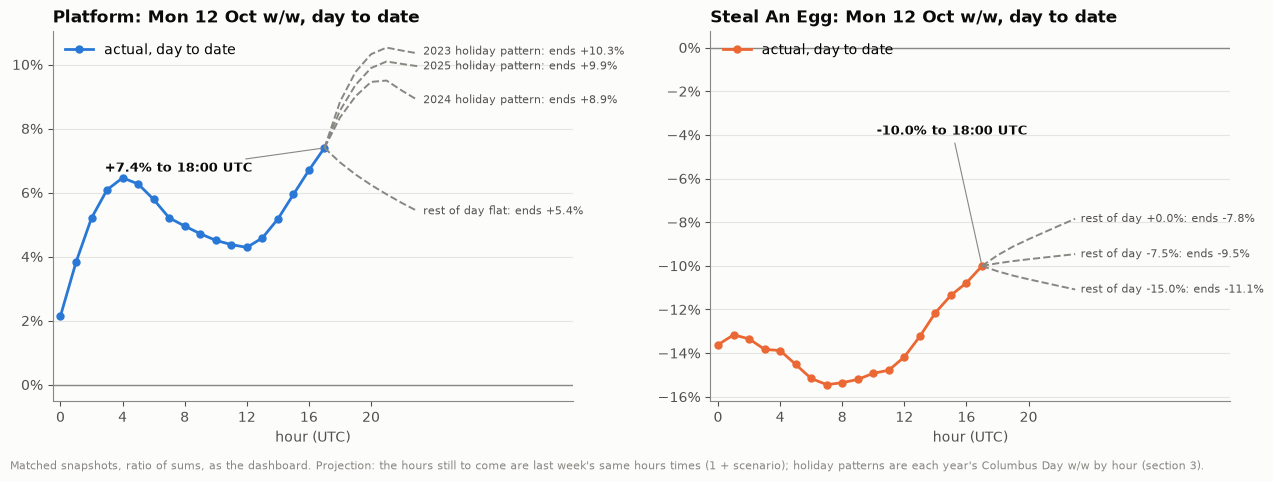

In [7]:
SCENARIOS = {
    "Platform": {"rest of day flat": 0.0} | {f"{y} holiday pattern": p for y, p in hol_pattern.items()},
    "Steal An Egg": {f"rest of day {g:+.1%}": g for g in [0.0, -0.075, -0.15]},
}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, (name, s) in zip(axes, series.items()):
    color = SERIES_COLOR[name]
    m = matched_hourly(s, DAY)
    path = m["cur"].cumsum() / m["base"].cumsum() - 1
    ax.plot(path.index, path, color=color, marker="o", markersize=5, label="actual, day to date")
    last_h = path.index.max()
    if last_h < 23:
        # Remaining hours: last week's hourly average x 6 snapshots, scaled by the scenario.
        rest = hourly(s, BASE).loc[last_h + 1:] * 6
        ends = []
        for label, g in SCENARIOS[name].items():
            g = g.loc[rest.index] if isinstance(g, pd.Series) else g  # hourly pattern or a flat rate
            cum_cur = pd.concat([m["cur"], rest * (1 + g)]).cumsum()
            cum_base = pd.concat([m["base"], rest]).cumsum()
            proj = (cum_cur / cum_base - 1).loc[last_h:]
            ax.plot(proj.index, proj, color=MUTED, ls="--", lw=1.4)
            ends.append([proj.iloc[-1], f"{label}: ends {proj.iloc[-1]:+.1%}"])
        ends.sort()
        lo, hi = ax.get_ylim()
        for i in range(1, len(ends)):
            ends[i][0] = max(ends[i][0], ends[i - 1][0] + 0.05 * (hi - lo))
        for y, text in ends:
            ax.annotate(text, (23, y), xytext=(4, 0), textcoords="offset points", va="center", fontsize=8, color=INK2)
    ax.annotate(f"{path.iloc[-1]:+.1%} to {last_h + 1:02d}:00 UTC", (last_h, path.iloc[-1]),
                xytext=(0.10, 0.62) if name == "Platform" else (0.32, 0.72), textcoords="axes fraction",
                fontsize=9, color=INK, fontweight="bold", arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
    ax.axhline(0, color=MUTED, lw=1)
    pct_axis(ax, 0)
    ax.set_xlim(-0.5, 33)
    ax.set_xticks(range(0, 24, 4))
    ax.set_xlabel("hour (UTC)")
    ax.set_title(f"{name}: {DAY:%a %d %b} w/w, day to date")
    ax.legend(loc="upper left")
source_note(fig, "Matched snapshots, ratio of sums, as the dashboard. Projection: the hours still to come are last week's same hours "
                 "times (1 + scenario); holiday patterns are each year's Columbus Day w/w by hour (section 3).")
fig.tight_layout(rect=(0, 0.03, 1, 1))

## 5. Daily w/w, last two weeks (the dashboard's view)

Each complete UTC day against the same weekday a week earlier. The latest day is partial and is drawn hollow.

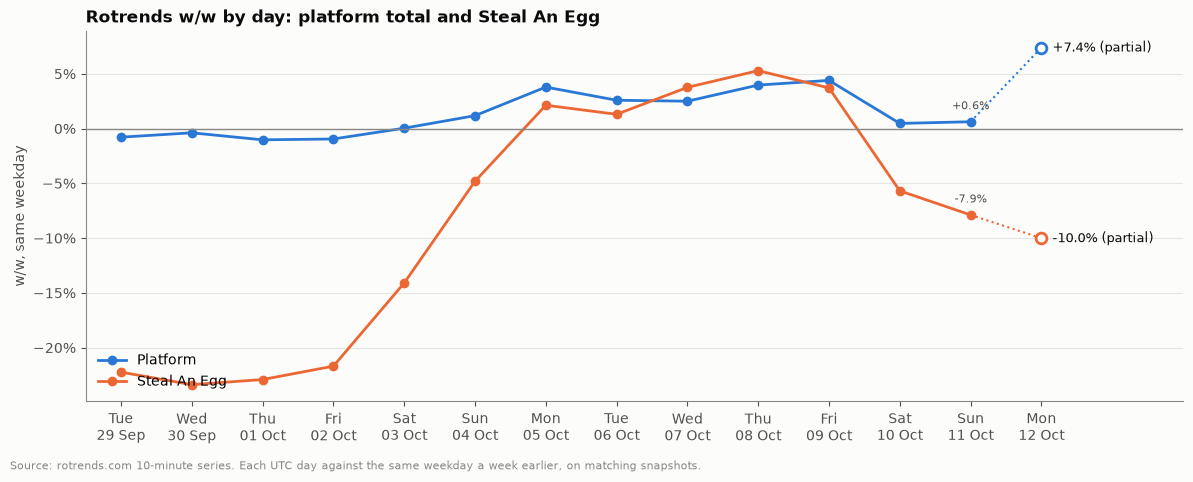

In [8]:
fig, ax = plt.subplots(figsize=(12, 4.8))
days = pd.date_range(DAY - pd.Timedelta(days=13), DAY)
for name, s in series.items():
    color = SERIES_COLOR[name]
    ww = pd.Series({d: matched_ww(s, d)[0] for d in days})
    ax.plot(ww.index[:-1], ww.iloc[:-1], color=color, marker="o", markersize=6, label=name)
    ax.plot(ww.index[-2:], ww.iloc[-2:], color=color, ls=":", lw=1.5)
    ax.scatter([ww.index[-1]], [ww.iloc[-1]], s=60, facecolor="#fcfcfb", edgecolor=color, linewidth=2, zorder=3)
    ax.annotate(f"{ww.iloc[-1]:+.1%} (partial)", (ww.index[-1], ww.iloc[-1]), xytext=(8, 0), textcoords="offset points",
                va="center", fontsize=9, color=INK)
    ax.annotate(f"{ww.iloc[-2]:+.1%}", (ww.index[-2], ww.iloc[-2]), xytext=(0, 9), textcoords="offset points",
                ha="center", fontsize=8, color=INK2)
ax.axhline(0, color=MUTED, lw=1)
pct_axis(ax)
ax.set_xlim(days[0] - pd.Timedelta(hours=12), days[-1] + pd.Timedelta(days=2))
ax.set_xticks(days)
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%a\n%d %b"))
ax.set_title("Rotrends w/w by day: platform total and Steal An Egg")
ax.set_ylabel("w/w, same weekday")
ax.legend(loc="lower left")
source_note(fig, "Source: rotrends.com 10-minute series. Each UTC day against the same weekday a week earlier, on matching snapshots.")
fig.tight_layout(rect=(0, 0.03, 1, 1))

## 6. Steal An Egg: is the decline real?

Daily average CCU from three independent sources:
- **Rotrends:** the 10-minute core-game series.
- **SRS scan:** `game_rank`, 2-hourly.
- **Rolimons:** `rolimons_game_universe`, averaged per day.

If the drop were a Rotrends artefact, SRS and Rolimons would not show it. The latest day is partial and dropped from the SRS and Rolimons lines.

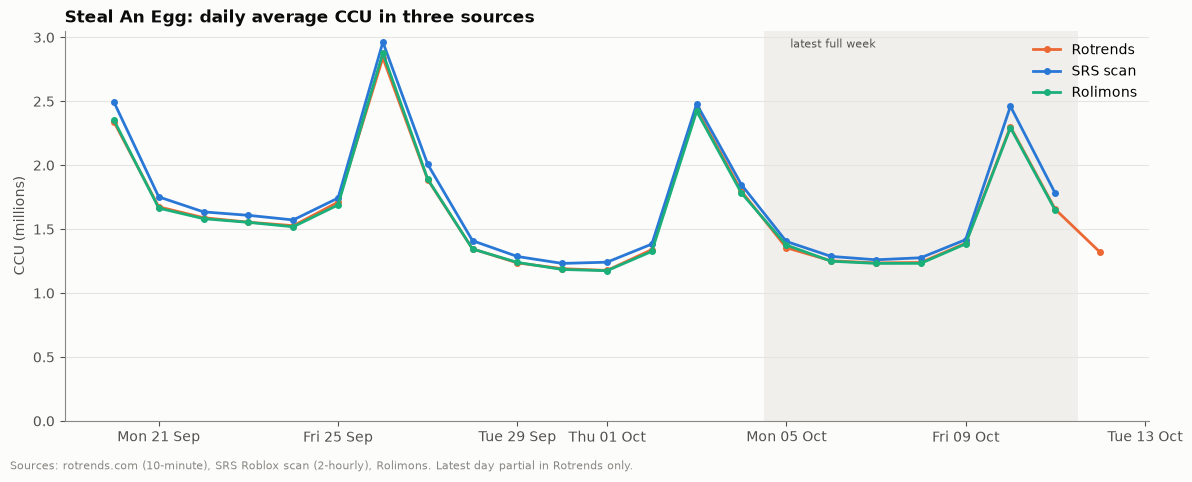

In [9]:
START = DAY - pd.Timedelta(days=22)
srs_egg = q(f'''
    SELECT rundate :: DATE AS date, AVG(players) AS ccu
    FROM (
        SELECT rundate, MAX(players) AS players
        FROM bots.rblx.game_rank
        WHERE universe_id = {STEAL_AN_EGG} AND file_name ILIKE '%scan%' AND rundate >= '{START:%Y-%m-%d}'
        GROUP BY 1
    )
    GROUP BY 1
''').set_index("date")["ccu"]
rol_egg = q(f'''
    SELECT runtime :: DATE AS date, AVG(players) AS ccu
    FROM bots.rblx.rolimons_game_universe
    WHERE universe_id = {STEAL_AN_EGG} AND runtime >= '{START:%Y-%m-%d}'
    GROUP BY 1
''').set_index("date")["ccu"]
rt_egg = series["Steal An Egg"].resample("D").mean()
egg_daily = pd.DataFrame({"Rotrends": rt_egg, "SRS scan": srs_egg, "Rolimons": rol_egg}).sort_index().loc[START:]
egg_daily.loc[DAY, ["SRS scan", "Rolimons"]] = None  # partial day

fig, ax = plt.subplots(figsize=(12, 4.8))
for col, color in zip(egg_daily.columns, [ORANGE, BLUE, AQUA]):
    s = egg_daily[col].dropna()
    ax.plot(s.index, s / 1e6, color=color, marker="o", markersize=4, label=col)
ax.axvspan(WEEK_START - pd.Timedelta(hours=12), WEEK_END + pd.Timedelta(hours=12), color=SHADE, lw=0, zorder=0)
ax.text(WEEK_START, 0.98, " latest full week", transform=ax.get_xaxis_transform(), fontsize=8, color=INK2, va="top")
ax.set_title("Steal An Egg: daily average CCU in three sources")
ax.set_ylabel("CCU (millions)")
ax.set_ylim(bottom=0)
ax.legend(loc="upper right")
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%a %d %b"))
source_note(fig, "Sources: rotrends.com (10-minute), SRS Roblox scan (2-hourly), Rolimons. Latest day partial in Rotrends only.")
fig.tight_layout(rect=(0, 0.03, 1, 1))

weekly = egg_daily.loc[:WEEK_END].resample("W-SUN").mean()
weekly = weekly[weekly.index >= START + pd.Timedelta(days=6)]
weekly.index = weekly.index.strftime("w/e %a %d %b")
pd.concat({"avg CCU": weekly, "w/w": weekly.pct_change()}, axis=1).style.format("{:,.0f}", subset=["avg CCU"]).format("{:+.1%}", subset=["w/w"], na_rep="")

Copies of the game ("Steal a ... Egg") from the per-game Rotrends list, weekly average CCU (estimated daily average). Players moving to copies would show up here.

In [10]:
clones = q(f'''
    SELECT game_id, MAX_BY(game_name, date) AS game_name, date, players_avg_est
    FROM bots.rblx.rotrend_games_adj
    WHERE game_name ILIKE '%steal%egg%'
        AND game_id <> {STEAL_AN_EGG}
        AND date BETWEEN '{WEEK_START - pd.Timedelta(days=7):%Y-%m-%d}' AND '{WEEK_END:%Y-%m-%d}'
    GROUP BY game_id, date, players_avg_est
''')
clones["week"] = clones["date"].dt.to_period("W-SUN").dt.end_time.dt.normalize()
cw = clones.pivot_table(index="game_id", columns="week", values="players_avg_est", aggfunc="sum").fillna(0) / 7
cw.columns = [f"w/e {c:%d %b}" for c in cw.columns]
cw["name"] = clones.groupby("game_id")["game_name"].last()
prev, last = cw.columns[0], cw.columns[1]
print(f"{len(cw):,} copies; combined weekly avg CCU {cw[prev].sum():,.0f} -> {cw[last].sum():,.0f} ({cw[last].sum() / cw[prev].sum() - 1:+.0%})")
top = cw.sort_values(last, ascending=False).head(8)
top.assign(**{"w/w": top[last] / top[prev] - 1}).style.format({prev: "{:,.0f}", last: "{:,.0f}", "w/w": "{:+.0%}"}).hide(axis="index")

84 copies; combined weekly avg CCU 75,639 -> 164,802 (+118%)


w/e 04 Oct,w/e 11 Oct,name,w/w
"23,353","72,112",Break and Steal an Egg,+209%
"7,093","19,451",Steal Animal Egg,+174%
"1,830","9,139",Steal an Clown Egg,+399%
391,"8,619",💀 Steal An EXE Egg! 💀,+2104%
"6,796","7,595",Clone to Steal Eggs,+12%
186,"6,028",Don't Steal My Eggs!,+3136%
"4,298","4,456",Steal an Egg for Squishy Dumplings!,+4%
"2,456","3,791",Steal A Baddie Egg!,+54%


## 7. What moved the per-game Rotrends total over the latest full week

Per-game Rotrends (`rotrend_games_adj`, estimated daily average) for the latest full Monday-to-Sunday week against the week before. The ten biggest gains and declines in CCU are cross-checked against the SRS scan and Rolimons over the same days. Each source's weekly average is its daily averages summed over the week and divided by 7, so a missing day counts as zero.

Where Rotrends' w/w differs from SRS and Rolimons, which agree with each other, the per-game Rotrends estimate is off rather than the game having moved.

In [11]:
rt = q(f'''
    SELECT game_id AS universe_id, game_name, date, players_avg_est AS ccu
    FROM bots.rblx.rotrend_games_adj
    WHERE date BETWEEN '{WEEK_START - pd.Timedelta(days=7):%Y-%m-%d}' AND '{WEEK_END:%Y-%m-%d}'
''')
rt["week"] = (rt["date"] >= WEEK_START).map({True: "this", False: "prev"})


def weekly_by_game(df: pd.DataFrame) -> pd.DataFrame:
    w = df.pivot_table(index="universe_id", columns="week", values="ccu", aggfunc="sum").fillna(0) / 7
    return w.reindex(columns=["prev", "this"], fill_value=0)


rt_w = weekly_by_game(rt)
rt_w["delta"] = rt_w["this"] - rt_w["prev"]
tot = rt_w[["prev", "this"]].sum()
print(f"Per-game Rotrends total: {tot['prev']:,.0f} -> {tot['this']:,.0f} ({tot['this'] / tot['prev'] - 1:+.1%})")
movers = pd.concat([rt_w.nlargest(10, "delta"), rt_w.nsmallest(10, "delta")])
ids = ", ".join(str(int(i)) for i in movers.index)
day_range = f"'{WEEK_START - pd.Timedelta(days=7):%Y-%m-%d}' AND '{WEEK_END:%Y-%m-%d}'"
srs = q(f'''
    SELECT universe_id, rundate :: DATE AS date, AVG(players) AS ccu
    FROM (
        SELECT universe_id, rundate, MAX(players) AS players
        FROM bots.rblx.game_rank
        WHERE universe_id IN ({ids}) AND file_name ILIKE '%scan%' AND rundate :: DATE BETWEEN {day_range}
        GROUP BY 1, 2
    )
    GROUP BY 1, 2
''')
rol = q(f'''
    SELECT universe_id, runtime :: DATE AS date, AVG(players) AS ccu
    FROM bots.rblx.rolimons_game_universe
    WHERE universe_id IN ({ids}) AND runtime :: DATE BETWEEN {day_range}
    GROUP BY 1, 2
''')
for df in (srs, rol):
    df["week"] = (df["date"] >= WEEK_START).map({True: "this", False: "prev"})
names = rt.sort_values("date").groupby("universe_id")["game_name"].last()


def plain_name(name: str) -> str:
    """Drop emoji (the chart font has none) and any brackets they leave empty."""
    name = "".join(ch for ch in name if ord(ch) <= 0xFFFF and not 0x2600 <= ord(ch) <= 0x27BF and ch != "\ufe0f")
    return " ".join(name.replace("[]", "").split())[:32]


check = pd.DataFrame({
    "game": names.reindex(movers.index).map(plain_name),
    "Rotrends CCU": movers["this"],
    "change": movers["delta"],
    "Rotrends w/w": movers["this"] / movers["prev"] - 1,
})
for label, df in [("SRS w/w", srs), ("Rolimons w/w", rol)]:
    w = weekly_by_game(df).reindex(movers.index)
    check[label] = w["this"] / w["prev"] - 1
check = check.replace([float("inf")], float("nan"))
check.style.format({"Rotrends CCU": "{:,.0f}", "change": "{:+,.0f}", "Rotrends w/w": "{:+.0%}",
                    "SRS w/w": "{:+.0%}", "Rolimons w/w": "{:+.0%}"}, na_rep="new / n.a.").hide(axis="index")

Per-game Rotrends total: 11,324,563 -> 11,433,073 (+1.0%)


game,Rotrends CCU,change,Rotrends w/w,SRS w/w,Rolimons w/w
Huss Valley,"103,328","+82,176",+389%,+256%,+327%
Dandy's World [ALPHA],"143,391","+49,924",+53%,+47%,+46%
Adopt Me!,"219,250","+49,563",+29%,+30%,+33%
Break and Steal an Egg,"72,112","+48,759",+209%,+185%,+199%
99 Nights in the Forest,"218,172","+38,982",+22%,+23%,+24%
Steal An Egg,"1,490,906","+30,473",+2%,+0%,-1%
Anime Zero [SHADOW MONARCH],"24,193","+24,193",new / n.a.,+2560%,+1323%
Survive a Million Monkeys,"24,145","+22,738",+1617%,new / n.a.,new / n.a.
+1 Stone Skipping,"34,985","+17,916",+105%,+122%,+162%
Firefighting Sim,"14,753","+14,265",+2924%,new / n.a.,new / n.a.


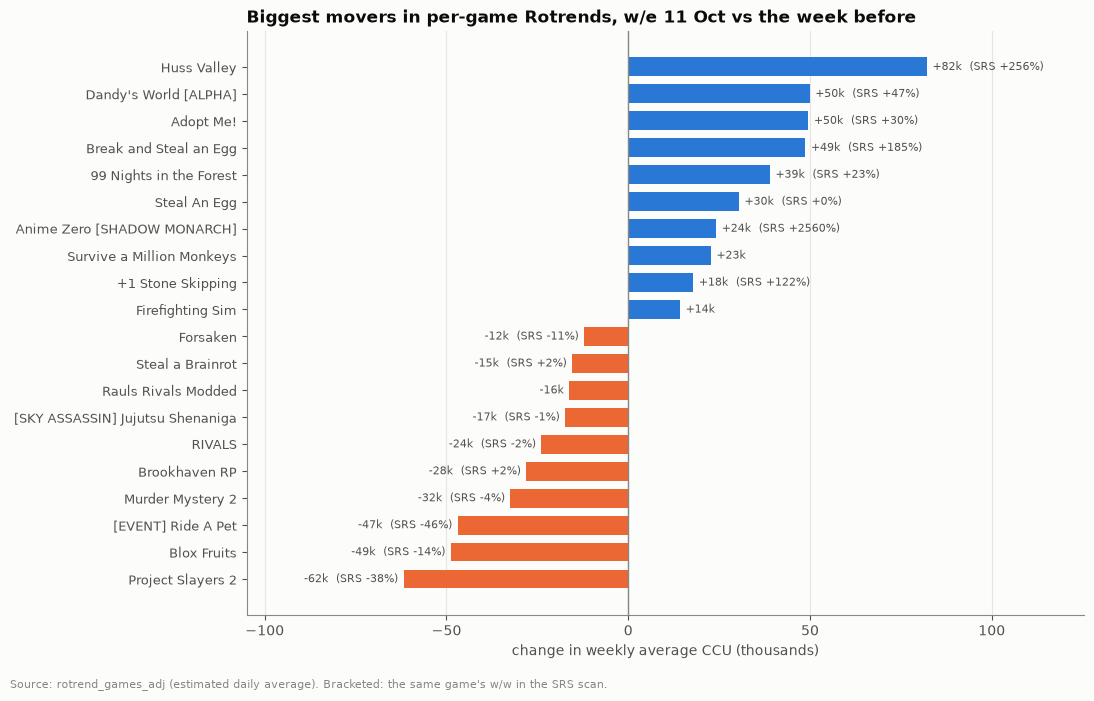

In [12]:
c = check.sort_values("change")
fig, ax = plt.subplots(figsize=(11, 7))
colors = [BLUE if v > 0 else ORANGE for v in c["change"]]
ax.barh(range(len(c)), c["change"] / 1e3, color=colors, height=0.7)
ax.set_yticks(range(len(c)))
ax.set_yticklabels(c["game"], fontsize=9)
for i, (v, srs_ww) in enumerate(zip(c["change"], c["SRS w/w"])):
    label = f"{v / 1e3:+.0f}k" + (f"  (SRS {srs_ww:+.0%})" if pd.notna(srs_ww) else "")
    ax.annotate(label, (v / 1e3, i), xytext=(4 if v > 0 else -4, 0), textcoords="offset points",
                ha="left" if v > 0 else "right", va="center", fontsize=8, color=INK2)
ax.axvline(0, color=MUTED, lw=1)
ax.grid(axis="x", color=GRID)
ax.grid(axis="y", visible=False)
ax.margins(x=0.3)
ax.set_xlabel("change in weekly average CCU (thousands)")
ax.set_title(f"Biggest movers in per-game Rotrends, w/e {WEEK_END:%d %b} vs the week before")
source_note(fig, "Source: rotrend_games_adj (estimated daily average). Bracketed: the same game's w/w in the SRS scan.")
fig.tight_layout(rect=(0, 0.03, 1, 1))